# 05 · Série real (Electricity): clássicos × LSTM × SSM × Mamba

Este notebook **não treina nada**: ele junta os resultados já salvos e gera os gráficos da comparação.

**Pré-requisitos** (na pasta do projeto, com o venv ativado):

```bash
python run_model.py configs/exp_real_classicos.json        # ARIMA e regressão com lags
python run_neurais.py configs/exp_real_neurais.json       # LSTM, SSM e Mamba (demora; é retomável)
```

Roteiro:
1. Leitura dos resultados
2. Tabela comparativa
3. RMSE × contexto (todas as abordagens)
4. MAE × contexto
5. Custo: tempo de treino e número de parâmetros
6. Previsão × real das redes (série completa + zoom)
7. Curvas de aprendizado
8. O kernel aprendido pelo SSM (Kₖ = C Āᵏ B̄)

## 1. Leitura dos resultados

In [1]:
from pathlib import Path
import json

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
RES = ROOT / "results"
FIG_DIR = RES / "figuras"; FIG_DIR.mkdir(parents=True, exist_ok=True)

ZOOM_INICIO = 1000     # horas a partir do início do teste
ZOOM_HORAS = 168       # 1 semana
L_ZOOM = 720           # contexto usado no gráfico de previsão (o maior testado)

cla = pd.read_csv(RES / "exp_real_classicos_results.csv")
neu = pd.read_csv(RES / "exp_real_neurais_results.csv")
met = pd.concat([cla, neu], ignore_index=True)

prev = dict(np.load(RES / "exp_real_classicos_predictions.npz"))
prev.update(np.load(RES / "exp_real_neurais_predictions.npz"))
hist = json.loads((RES / "exp_real_neurais_history.json").read_text(encoding="utf-8"))
cfg = json.loads((RES / "exp_real_neurais_config.json").read_text(encoding="utf-8"))

serie = pd.read_csv(ROOT / cfg["data"]["path"])["y"].to_numpy()
n = len(serie)
train_end = int(n * cfg["experiment"]["train_ratio"])
val_end = train_end + int(n * cfg["experiment"]["validation_ratio"])
t_teste = np.arange(val_end, n)
y_real = prev["true"]
print(f"teste: {val_end}–{n-1} ({len(y_real)} pontos)")
print("modelos:", sorted(met.model.unique()))

teste: 21042–26303 (5262 pontos)
modelos: ['arima', 'linear_regression', 'lstm', 'mamba', 'ssm']


### Estilo (mesmo tema escuro dos slides)

In [2]:
BG, FG, MUTED, GRID = "#0E1117", "#E6E8EE", "#8B93A1", "#232B38"
plt.rcParams.update({
    "figure.facecolor": BG, "axes.facecolor": BG, "axes.edgecolor": MUTED,
    "axes.labelcolor": FG, "xtick.color": MUTED, "ytick.color": MUTED, "text.color": FG,
    "axes.grid": True, "grid.color": GRID, "grid.linewidth": 0.8,
    "axes.spines.top": False, "axes.spines.right": False,
    "font.size": 15, "legend.frameon": False, "savefig.dpi": 200,
})

# cor, marcador e nome de cada abordagem (sempre os mesmos em todos os gráficos)
ESTILO = {
    "linear_regression": dict(cor="#8FA8FF", mk="o", nome="Regressão com lags"),
    "lstm":              dict(cor="#B9BEC8", mk="s", nome="LSTM"),
    "ssm":               dict(cor="#6FCF97", mk="^", nome="SSM (S4D)"),
    "mamba":             dict(cor="#D09CFA", mk="D", nome="Mamba"),
}
COR_ARIMA = "#F2A65A"
COM_CONTEXTO = list(ESTILO)

def salvar(fig, nome):
    caminho = FIG_DIR / f"{nome}.png"
    fig.savefig(caminho, bbox_inches="tight")
    print("figura salva em", caminho.relative_to(ROOT))

def rmse(a, b):
    return float(np.sqrt(np.mean((np.asarray(a) - np.asarray(b)) ** 2)))

def linhas_por_contexto(ax, coluna, anotar_melhor=True):
    ctxs = sorted(met.loc[met.model == "lstm", "context_length"].astype(int))
    for m in COM_CONTEXTO:
        d = met[met.model == m].sort_values("context_length")
        e = ESTILO[m]
        ax.plot(d.context_length, d[coluna], marker=e["mk"], color=e["cor"], lw=2.2, ms=8, label=e["nome"])
    ax.set_xscale("log"); ax.set_xticks(ctxs); ax.set_xticklabels(ctxs); ax.minorticks_off()
    ax.set_xlabel("tamanho do contexto L (escala log)")
    for lag in (24, 168, 720):
        ax.axvline(lag, color=MUTED, lw=0.8, ls=":", zorder=0)
    return ctxs

## 2. Tabela comparativa

Uma linha por (modelo, contexto). O ARIMA não tem contexto (`NaN`).

In [3]:
cols = ["model", "context_length", "mae", "rmse", "train_time_s", "inference_time_s", "parameters"]
tab = met[cols].sort_values(["model", "context_length"]).reset_index(drop=True)
tab.round(4)

,model,context_length,mae,rmse,train_time_s,inference_time_s,parameters
0,arima,NaN,100.2277,147.9633,242.3008,1.1478,28
1,linear_regression,24.0,100.7444,148.5442,0.0277,0.0007,25
2,linear_regression,48.0,89.3765,136.3658,0.0471,0.0009,49
3,linear_regression,96.0,85.7200,131.0312,0.1035,0.0152,97
4,linear_regression,168.0,79.5955,123.8391,0.1907,0.0042,169
5,linear_regression,336.0,75.6071,118.7835,0.4407,0.0061,337
6,linear_regression,720.0,74.2948,116.7554,1.0986,0.0139,721
7,lstm,24.0,103.5118,144.4989,59.2800,0.1882,50497
8,lstm,48.0,106.7767,148.8885,120.5239,0.5652,50497
9,lstm,96.0,106.9561,148.6461,140.8060,0.8562,50497


In [4]:
# visão "larga": RMSE de cada abordagem em cada contexto
larga = met[met.model.isin(COM_CONTEXTO)].pivot(index="context_length", columns="model", values="rmse")[COM_CONTEXTO]
larga.index = larga.index.astype(int)
larga["ARIMA (sem contexto)"] = float(met.loc[met.model == "arima", "rmse"].iloc[0])
print("RMSE no teste:")
larga.round(4)

RMSE no teste:


model,linear_regression,lstm,ssm,mamba,ARIMA (sem contexto)
context_length,,,,,
24,148.5442,144.4989,143.2096,147.6827,147.9633
48,136.3658,148.8885,134.6636,145.4764,147.9633
96,131.0312,148.6461,127.2089,146.7191,147.9633
168,123.8391,145.8804,125.5269,144.5821,147.9633
336,118.7835,146.8983,126.2153,145.3742,147.9633
720,116.7554,147.9325,125.0153,149.9067,147.9633


## 3. RMSE × contexto

As linhas pontilhadas verticais marcam os ciclos diário (24), semanal (168) e mensal (720). O ARIMA aparece como linha horizontal: ele não usa janela de contexto.

figura salva em results/figuras/real_comparacao_rmse_contexto.png


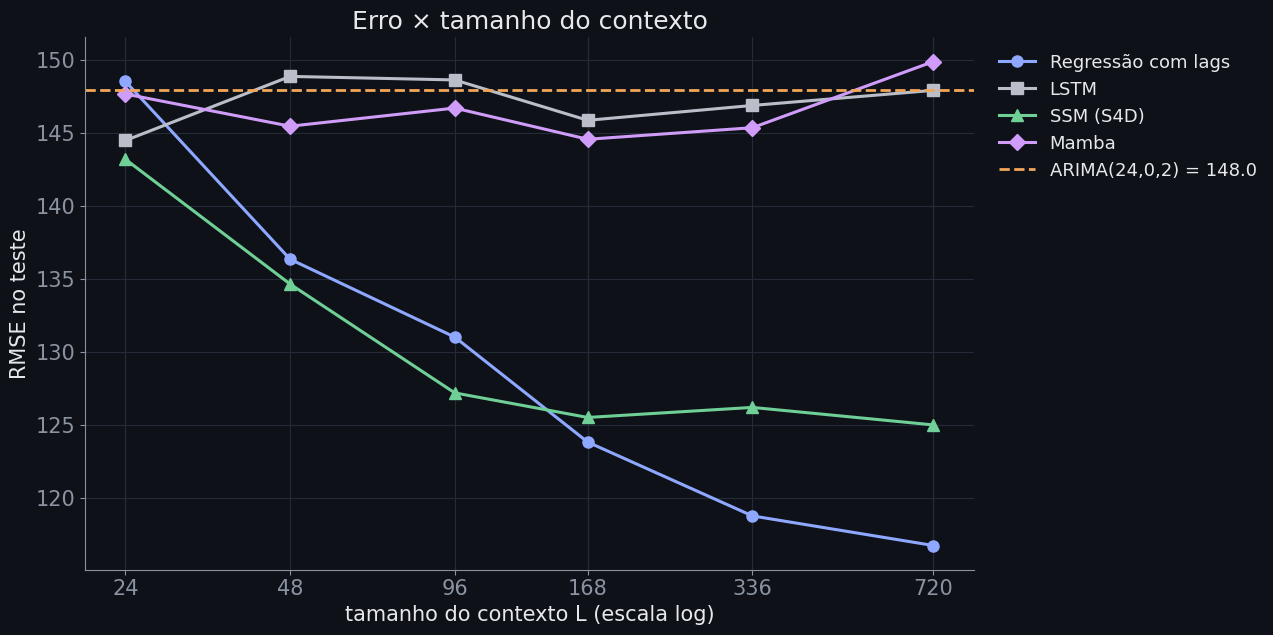

In [5]:
fig, ax = plt.subplots(figsize=(13, 6.6))
linhas_por_contexto(ax, "rmse")
arima = float(met.loc[met.model == "arima", "rmse"].iloc[0])
ax.axhline(arima, color=COR_ARIMA, ls="--", lw=2, label=f"ARIMA(24,0,2) = {arima:.1f}")
ax.set(ylabel="RMSE no teste", title="Erro × tamanho do contexto")
ax.legend(loc="upper left", bbox_to_anchor=(1.01, 1.0), fontsize=13)
fig.tight_layout(); salvar(fig, "real_comparacao_rmse_contexto"); plt.show()

### 3b. Uma régua para interpretar o RMSE

Para saber **quais dependências** cada modelo conseguiu usar, ajustamos (no treino, por mínimos quadrados) regressões que só enxergam alguns lags e medimos o RMSE no teste. Isso dá uma "escada": cada degrau é o erro de quem usa aquele conjunto de lags. Um modelo cujo RMSE fica entre dois degraus usou parcialmente o lag do degrau de baixo.

só lag 1                 RMSE = 170.6
lags 1 e 24              RMSE = 164.2
lags 1, 24 e 168         RMSE = 154.5
lags 1, 24, 168 e 720    RMSE = 154.6


figura salva em results/figuras/real_comparacao_rmse_regua.png


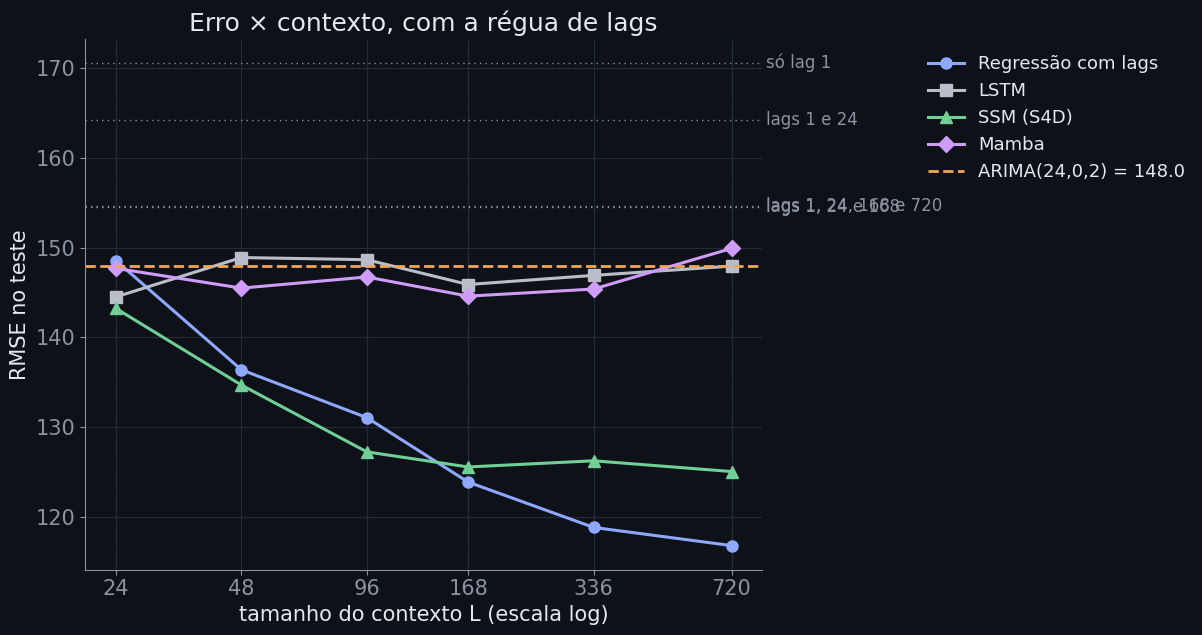

In [6]:
def rmse_com_lags(lags):
    t_tr, t_te = np.arange(max(lags), train_end), np.arange(val_end, n)
    X = lambda t: np.column_stack([serie[t - l] for l in lags] + [np.ones(len(t))])
    b = np.linalg.lstsq(X(t_tr), serie[t_tr], rcond=None)[0]
    return rmse(serie[t_te], X(t_te) @ b)

ESCADA = {"só lag 1": [1], "lags 1 e 24": [1, 24], "lags 1, 24 e 168": [1, 24, 168], "lags 1, 24, 168 e 720": [1, 24, 168, 720]}
degraus = {k: rmse_com_lags(v) for k, v in ESCADA.items()}
for k, v in degraus.items():
    print(f"{k:24s} RMSE = {v:.1f}")

fig, ax = plt.subplots(figsize=(13, 6.6))
linhas_por_contexto(ax, "rmse")
ax.axhline(arima, color=COR_ARIMA, ls="--", lw=2, label=f"ARIMA(24,0,2) = {arima:.1f}")
for k, v in degraus.items():
    ax.axhline(v, color=MUTED, lw=1.0, ls=(0, (1, 3)))
    ax.text(1.005, v, k, transform=ax.get_yaxis_transform(), va="center", color=MUTED, fontsize=12)
ax.set(ylabel="RMSE no teste", title="Erro × contexto, com a régua de lags")
ax.legend(loc="upper left", bbox_to_anchor=(1.22, 1.0), fontsize=13)
fig.tight_layout(); salvar(fig, "real_comparacao_rmse_regua"); plt.show()

**No dado real a régua se comporta diferente:** regressões com só 2 a 4 lags ficam *acima* de todos os modelos (RMSE 155 a 171). Ou seja, a informação útil não está concentrada em poucos lags isolados como na série sintética: ela está espalhada pela janela (o formato da curva do dia, a semana inteira). Por isso os modelos que usam a janela toda ganham, e a régua serve só como referência.

## 4. MAE × contexto

figura salva em results/figuras/real_comparacao_mae_contexto.png


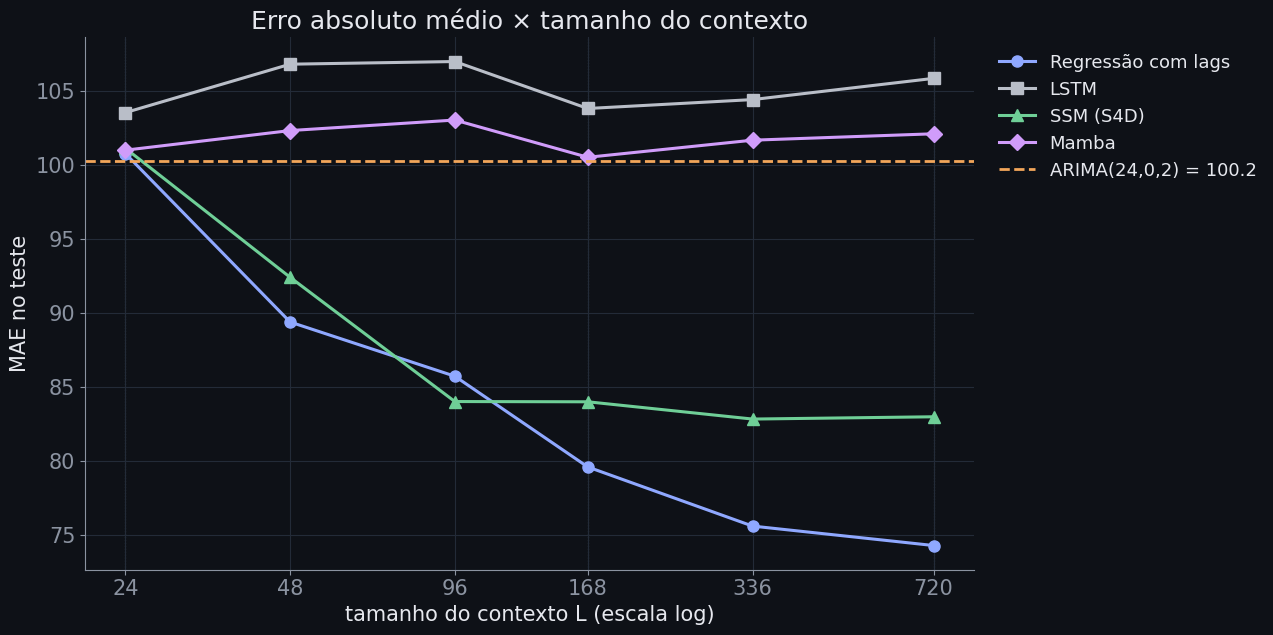

In [7]:
fig, ax = plt.subplots(figsize=(13, 6.6))
linhas_por_contexto(ax, "mae")
arima_mae = float(met.loc[met.model == "arima", "mae"].iloc[0])
ax.axhline(arima_mae, color=COR_ARIMA, ls="--", lw=2, label=f"ARIMA(24,0,2) = {arima_mae:.1f}")
ax.set(ylabel="MAE no teste", title="Erro absoluto médio × tamanho do contexto")
ax.legend(loc="upper left", bbox_to_anchor=(1.01, 1.0), fontsize=13)
fig.tight_layout(); salvar(fig, "real_comparacao_mae_contexto"); plt.show()

## 5. Custo: tempo de treino e número de parâmetros

Tempo em **escala log**, porque vai de frações de segundo (regressão) a minutos (redes). Os tempos dependem da máquina e da implementação: o Mamba aqui é a versão didática em PyTorch puro, sem o kernel CUDA do artigo.

figura salva em results/figuras/real_comparacao_custo.png


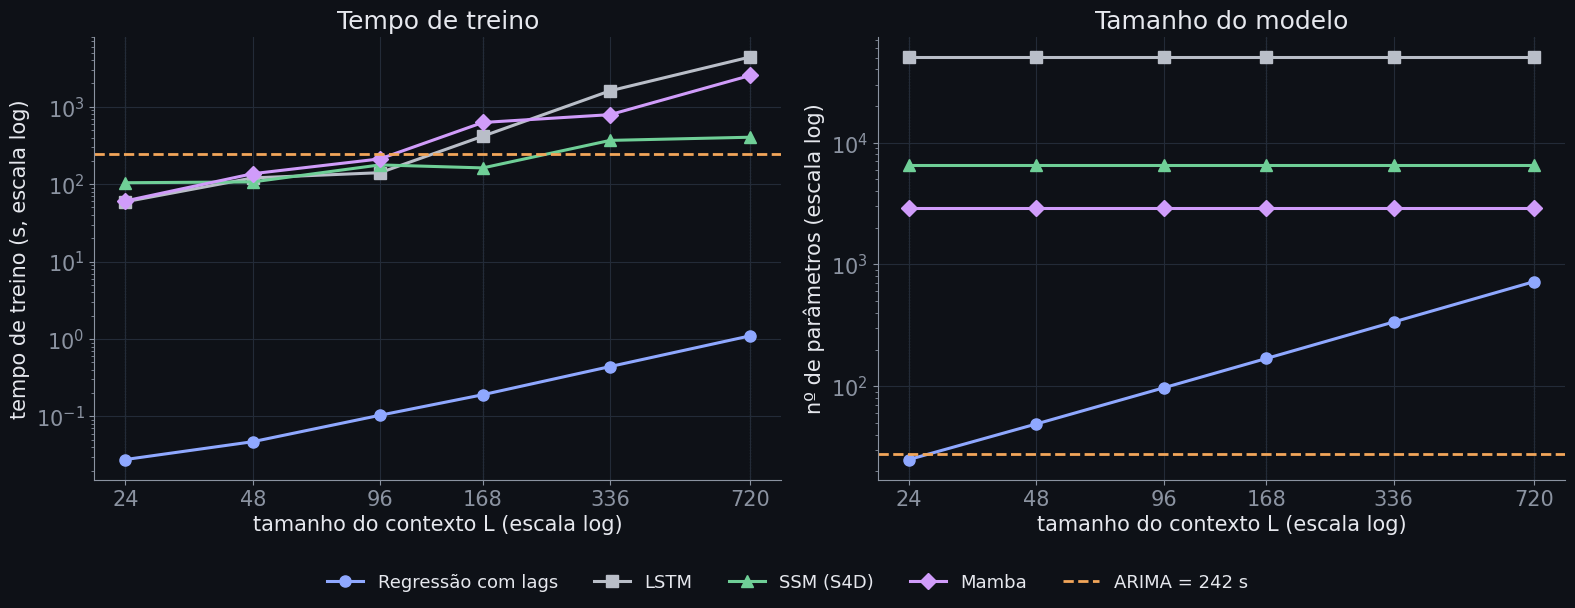

In [8]:
fig, (a0, a1) = plt.subplots(1, 2, figsize=(16, 6.2))

linhas_por_contexto(a0, "train_time_s")
t_arima = float(met.loc[met.model == "arima", "train_time_s"].iloc[0])
a0.axhline(t_arima, color=COR_ARIMA, ls="--", lw=2, label=f"ARIMA = {t_arima:.0f} s")
a0.set_yscale("log"); a0.set(ylabel="tempo de treino (s, escala log)", title="Tempo de treino")
h, l = a0.get_legend_handles_labels()

linhas_por_contexto(a1, "parameters")
a1.axhline(float(met.loc[met.model == "arima", "parameters"].iloc[0]), color=COR_ARIMA, ls="--", lw=2, label="ARIMA")
a1.set_yscale("log"); a1.set(ylabel="nº de parâmetros (escala log)", title="Tamanho do modelo")
fig.tight_layout(rect=(0, 0.08, 1, 1))
fig.legend(h, l, loc="lower center", ncol=5, fontsize=13)
salvar(fig, "real_comparacao_custo"); plt.show()

**Como ler:** nas redes, o número de parâmetros **não depende** do contexto (os mesmos pesos são aplicados em todos os passos da sequência); na regressão ele cresce com L (um coeficiente por lag). Já o tempo de treino das redes cresce com L, porque cada janela é mais longa.

## 6. Previsão × real das redes

Mesmo formato da figura dos clássicos: série completa em cima, zoom de uma semana embaixo. Contexto `L_ZOOM` (célula 1).

figura salva em results/figuras/real_neurais_previsao_completa.png


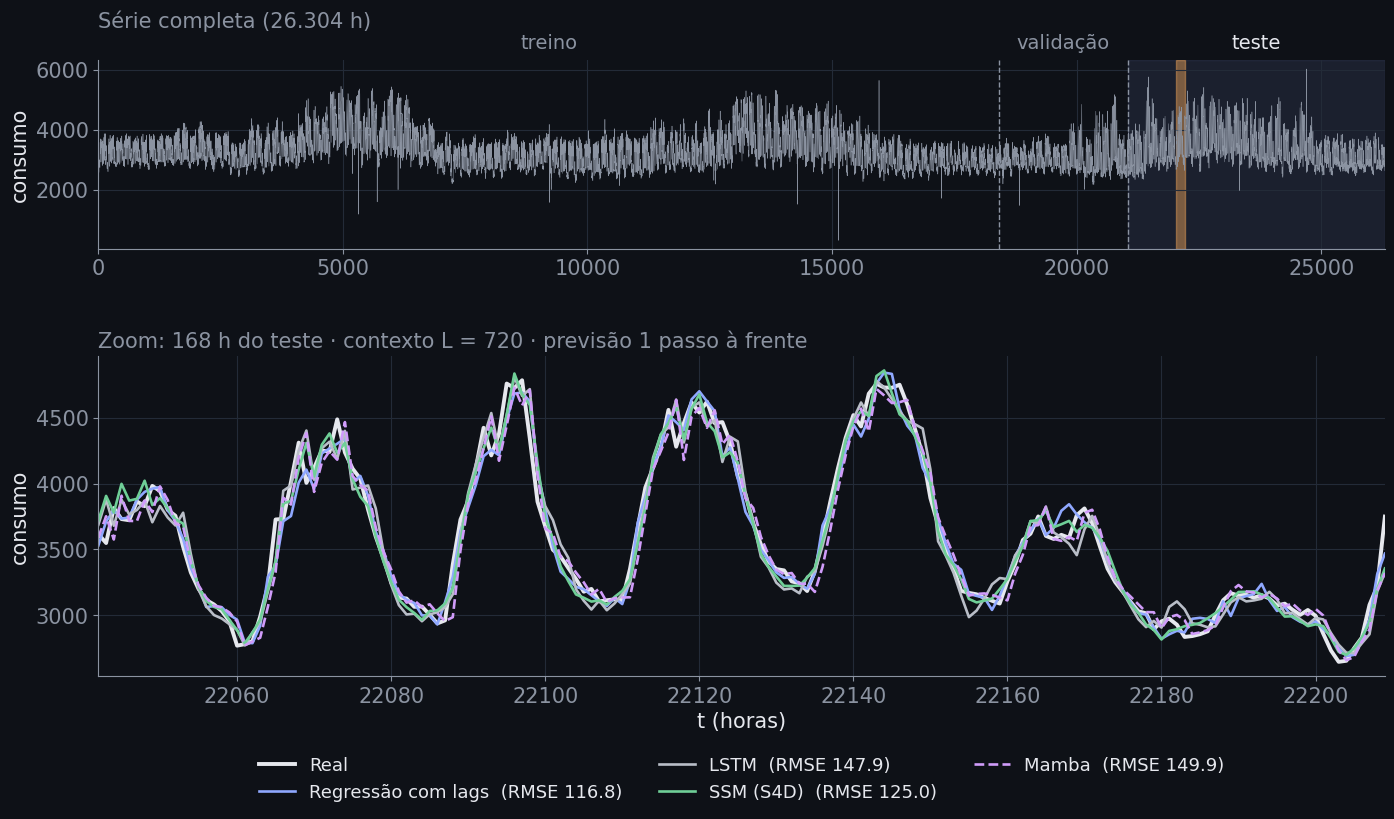

In [9]:
z = slice(ZOOM_INICIO, ZOOM_INICIO + ZOOM_HORAS)
tz = t_teste[z]

fig, (a0, a1) = plt.subplots(2, 1, figsize=(16.6, 8.0), gridspec_kw={"height_ratios": [1, 1.7], "hspace": 0.42})
a0.plot(np.arange(n), serie, color=MUTED, lw=0.35)
for ini, fim, nome in [(0, train_end, "treino"), (train_end, val_end, "validação"), (val_end, n, "teste")]:
    if nome == "teste":
        a0.axvspan(ini, fim, color="#8FA8FF", alpha=0.10)
    a0.text((ini + fim) / 2, 1.04, nome, transform=a0.get_xaxis_transform(), ha="center", va="bottom",
            color=FG if nome == "teste" else MUTED, fontsize=14)
for x in (train_end, val_end):
    a0.axvline(x, color=MUTED, lw=1, ls="--")
a0.axvspan(tz[0], tz[-1], color=COR_ARIMA, alpha=0.45)
a0.set(xlim=(0, n), ylabel="consumo")
a0.set_title(f"Série completa ({n:,} h)".replace(",", "."), loc="left", fontsize=15, color=MUTED, pad=24)

a1.plot(tz, y_real[z], color=FG, lw=2.8, label="Real")
for m, ls in [("linear_regression", "-"), ("lstm", "-"), ("ssm", "-"), ("mamba", "--")]:
    p = prev[f"{m}__{L_ZOOM}"]
    a1.plot(tz, p[z], color=ESTILO[m]["cor"], lw=1.9, ls=ls, label=f"{ESTILO[m]['nome']}  (RMSE {rmse(y_real, p):.1f})")
a1.set(xlim=(tz[0], tz[-1]), xlabel="t (horas)", ylabel="consumo")
a1.set_title(f"Zoom: {ZOOM_HORAS} h do teste · contexto L = {L_ZOOM} · previsão 1 passo à frente", loc="left", fontsize=15, color=MUTED)
a1.legend(loc="upper center", bbox_to_anchor=(0.5, -0.2), ncol=3, fontsize=13)
salvar(fig, "real_neurais_previsao_completa"); plt.show()

## 7. Curvas de aprendizado

Perda (MSE na escala normalizada) por época, no treino e na validação, para o contexto `L_ZOOM`. O treino para quando a validação não melhora por `patience` épocas, e o modelo volta para a melhor época.

figura salva em results/figuras/real_neurais_curvas_aprendizado.png


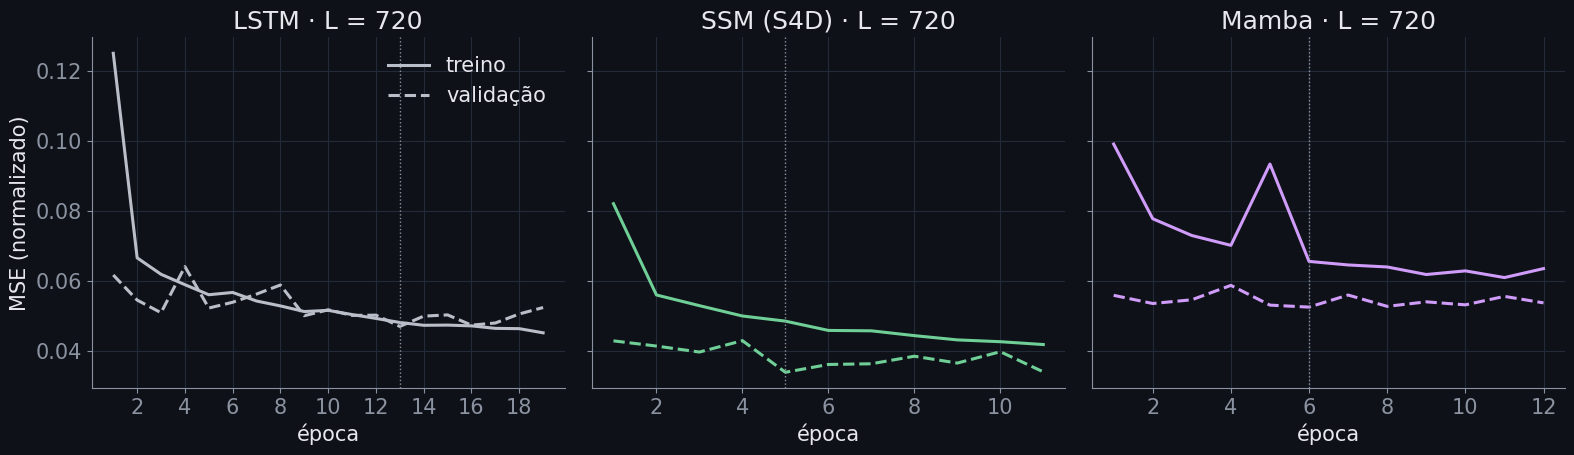

In [10]:
fig, axs = plt.subplots(1, 3, figsize=(16, 4.8), sharey=True)
for ax, m in zip(axs, ["lstm", "ssm", "mamba"]):
    h = hist[f"{m}__{L_ZOOM}"]
    ep = np.arange(1, len(h["train_loss"]) + 1)
    ax.plot(ep, h["train_loss"], color=ESTILO[m]["cor"], lw=2.2, label="treino")
    ax.plot(ep, h["val_loss"], color=ESTILO[m]["cor"], lw=2.2, ls="--", label="validação")
    melhor = int(np.argmin(h["val_loss"])) + 1
    ax.axvline(melhor, color=MUTED, lw=1, ls=":")
    ax.set(title=f"{ESTILO[m]['nome']} · L = {L_ZOOM}", xlabel="época")
    ax.xaxis.set_major_locator(plt.MaxNLocator(integer=True))
axs[0].set_ylabel("MSE (normalizado)"); axs[0].legend()
fig.tight_layout(); salvar(fig, "real_neurais_curvas_aprendizado"); plt.show()

## 8. O kernel aprendido pelo SSM

No SSM LTI a saída é uma convolução: yₜ = Σₖ Kₖ uₜ₋ₖ, com **Kₖ = C Āᵏ B̄**. O `run_model.py` salva o kernel da primeira camada (um por canal). Se o SSM aprendeu as dependências, deve haver peso perto dos lags 24, 168 e 720.

Mostramos a média de |Kₖ| nos canais, para o maior contexto disponível.

figura salva em results/figuras/real_ssm_kernel.png


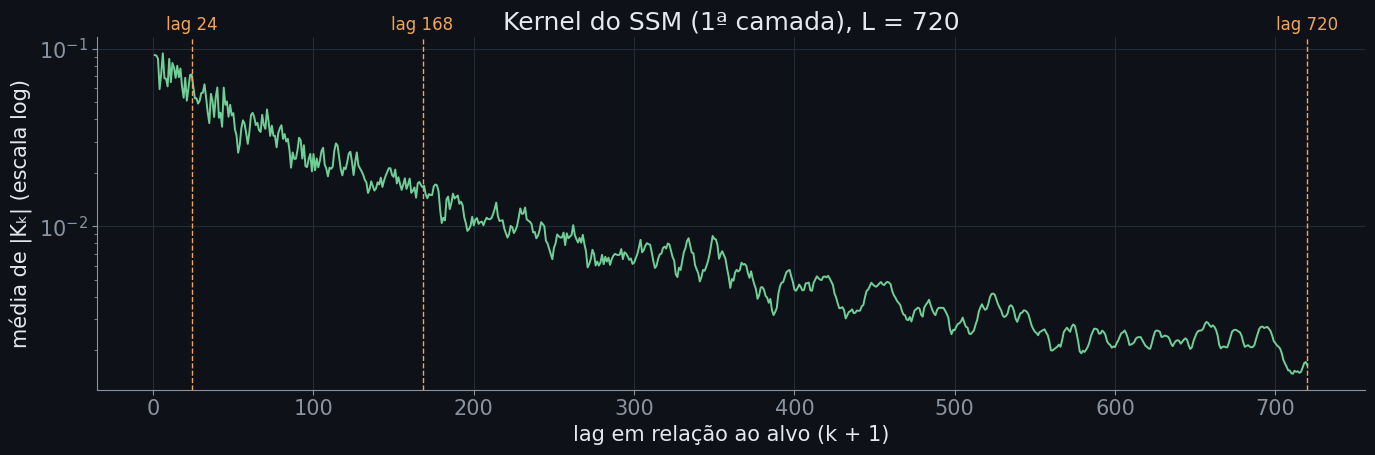

In [11]:
L_K = max(int(k.split("__")[1]) for k in prev if k.startswith("ssm__") and k.endswith("__kernel"))
K = prev[f"ssm__{L_K}__kernel"]                 # (canais, L)
k_med = np.abs(K).mean(axis=0)
lags = np.arange(1, len(k_med) + 1)             # K_0 pesa u_t, que é o lag 1 do alvo y_{t+1}

fig, ax = plt.subplots(figsize=(14, 4.8))
ax.plot(lags, k_med, color=ESTILO["ssm"]["cor"], lw=1.4)
for lag in (24, 168, 720):
    if lag <= len(k_med):
        ax.axvline(lag, color=COR_ARIMA, lw=1, ls="--")
        ax.text(lag, 1.02, f"lag {lag}", transform=ax.get_xaxis_transform(), ha="center", color=COR_ARIMA, fontsize=12)
ax.set_yscale("log")
ax.set(xlabel="lag em relação ao alvo (k + 1)", ylabel="média de |Kₖ| (escala log)", title=f"Kernel do SSM (1ª camada), L = {L_K}")
fig.tight_layout(); salvar(fig, "real_ssm_kernel"); plt.show()

**Como ler:** o kernel decai com k (memória que "esquece"), como no slide da memória (Āᵏ). Picos ou "ombros" perto dos lags 24 e 168 indicam que o SSM ajustou modos de oscilação nesses períodos (a parte imaginária de A no S4D). Esse gráfico só existe para o SSM: no Mamba o kernel muda a cada passo (Kₜ,ₖ), então não há um único kernel para desenhar.

## Figuras geradas

| arquivo | uso sugerido |
|---|---|
| `real_comparacao_rmse_contexto.png` | slide principal de resultados |
| `real_comparacao_rmse_regua.png` | discussão: quais lags cada modelo usou |
| `real_comparacao_mae_contexto.png` | complemento (mesma leitura do RMSE) |
| `real_comparacao_custo.png` | slide de custo computacional |
| `real_neurais_previsao_completa.png` | previsão × real das redes |
| `real_neurais_curvas_aprendizado.png` | discussão de treino / overfitting |
| `real_ssm_kernel.png` | ligação com a teoria (Kₖ = C Āᵏ B̄) |